In [9]:
import pandas as pd

train = pd.read_csv("/content/train.csv")
test = pd.read_csv("/content/test.csv")
sample_submission = pd.read_csv("/content/sample_submission.csv")

print(train.shape)
print(test.shape)

display(train.head())
train.info()

missing_rows = train.isna().any()
print(missing_rows)

(8693, 14)
(4277, 13)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB
PassengerId     False
HomePlanet       True
CryoSleep        True
Cabin            True
Destination      True
Age              True
VIP       

What does each row represent? - one passenger's trip information

What is the target column? - transported (if they were transported or not)

Which columns are numerical, categorical, or identifiers?

*   numerical: age, roomservice, foodcourt, shoppingmall, spa, vrdeck
*   categorical: homeplanet, cabin, destination, name
*   identifiers: passengerid, cryosleep, vip, transported


Which columns contain missing values? - HomePlanet, CryoSleep, Cabin, Destination, Age, VIP, RoomService, FoodCourt, ShoppingMall, Spa, VRDeck, Name

In [ ]:
train["Transported"].value_counts()

,count
Transported,
True,4378
False,4315


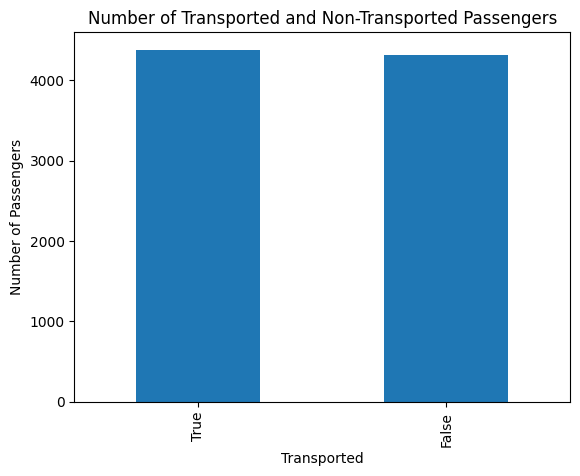

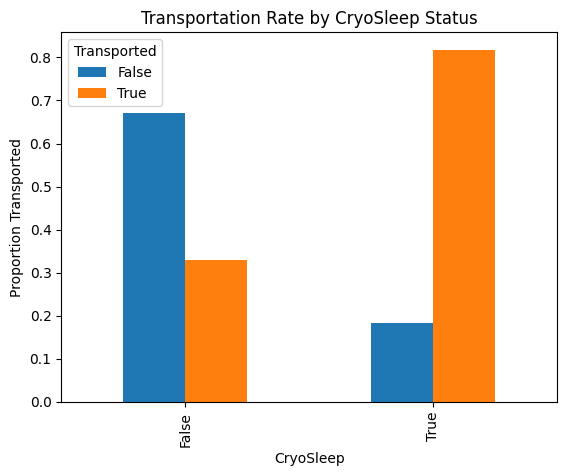

In [6]:
import matplotlib.pyplot as plt

train["Transported"].value_counts().plot(kind="bar")
plt.title("Number of Transported and Non-Transported Passengers")
plt.xlabel("Transported")
plt.ylabel("Number of Passengers")
plt.show()

pd.crosstab(
    train["CryoSleep"],
    train["Transported"],
    normalize="index"
).plot(kind="bar")

plt.title("Transportation Rate by CryoSleep Status")
plt.ylabel("Proportion Transported")
plt.show()

Observation: Proportion of successful transportations is highest when passengers are in cryosleep

In [ ]:
missing_values = train.isna().sum().sort_values(ascending=False)
missing_values[missing_values > 0]


,0
CryoSleep,217
ShoppingMall,208
VIP,203
HomePlanet,201
Name,200
Cabin,199
VRDeck,188
Spa,183
FoodCourt,183
Destination,182


* CryoSleep column: Use related information from another column and
copy pattern over. IE: CryoSleep passengers spend 0 as a pattern within the existing data, so it is safe to assume that passengers with unknown CryoSleep data and that also have exactly 0 as their spending value are probably asleep (True)

* ShoppingMall column: Substitute the missing value with the median for passengers that are not CryoSleep and/or are not under 13 years of age, as both categories have a spending value of exactly 0 when the values for those categories are true.

* VIP column: Create an unknown cateogory. VIP status may be important and implied from other data, so it would be better to keep and mark these rows in case future findings discovers a useful prediction pattern.